In [149]:
from scipy.io import loadmat

mat = loadmat('/home/yxf/proj/federatedlearning/Soccer Player.mat')  # 路径根据你的数据文件
X = mat['data']  # shape: [M, d]
partial_y = mat['partial_target'].T  # shape: [M, Q]
true_y = mat['target'].T  # shape: [M, Q]


print(X.shape)
print(partial_y.shape)
print(true_y)

(17472, 279)
(17472, 171)
[[1 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 1]
 [0 1 0 ... 0 0 0]
 ...
 [0 0 0 ... 0 0 1]
 [0 0 0 ... 0 0 1]
 [0 0 0 ... 0 0 1]]


In [150]:
import numpy as np

# 获取 ground-truth 标签
y_true = np.argmax(true_y, axis=1)  # shape: [M]
counts = np.zeros([partial_y.shape[1]])
for i in range(len(y_true)):
    counts[y_true[i]] += 1
print(counts)
# 获取候选标签集合（作为 mask）


from sklearn.model_selection import train_test_split

X_train, X_test, partial_y_train, partial_y_test, y_true_train, y_true_test = train_test_split(
    X, partial_y, y_true, test_size=0.2, random_state=42
)


candidate_mask = partial_y_train  # shape: [M, Q], 0/1 矩阵


[  74.   68.   54.   76.   65.  105.   52.   40.   40.   40.   22.   91.
   55.   18.   46.   74.   37.   38.   65.   54.   56.   61.   74.   41.
   50.   36.   65.  111.   38.   96.   78.   12.   20.   59.   12.   57.
   38.   48.   63.   49.   85.   49.   56.   41.   67.   51.   42.   79.
   26.   36.   32.   25.   58.   77.   57.   89.   42.   45.   16.   11.
   33.   72.   42.   29.   58.  229.   61.   19.   42.   42.   33.  123.
   18.   31.   14.   66.   60.   36.   11.   48.   40.   29.   67.   13.
  151.   88.   62.  140.   63.   65.   56.   15.   81.   30.   60.   40.
   15.   65.   63.   22.   56.   61.  142.   93.   24.  148.   62.   68.
   16.   14.   46.   52.   21.   42.  146.   19.   47.   15.   70.   57.
   41.   23.   48.   31.   31.   64.   16.   34.   45.   28.   48.   63.
   53.   53.   30.   59.   45.   46.   79.  148.   50.   73.   52.  166.
   19.   35.   27.   36.   24.   18.   47.   23.   23.   17.   25.   61.
   53.   22.   31.   32.   82.   55.   27.   15.   

In [151]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim.sgd
from torch.utils.data import DataLoader, TensorDataset
import numpy as np

class SimpleNet(nn.Module):
    def __init__(self, input_dim, num_classes):
        super(SimpleNet, self).__init__()
        self.fc1 = nn.Linear(input_dim, 256)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(256, num_classes)

    def forward(self, x):
        x = self.relu(self.fc1(x))
        return self.fc2(x)
import torch.nn as nn
import torch.nn.functional as F



class ProdenModel:
    def __init__(self, input_dim, num_classes, device='cuda' if torch.cuda.is_available() else 'cpu'):
        self.model = SimpleNet(input_dim, num_classes).to(device)
        self.num_classes = num_classes
        self.device = device

    def train(self, X, candidate_mask, epochs=100, batch_size=128, lr=1e-4):
        X = torch.tensor(X, dtype=torch.float32).to(self.device)
        candidate_mask = torch.tensor(candidate_mask, dtype=torch.float32).to(self.device)  # shape: [M, C]
        M = X.shape[0]
        C = self.num_classes

        # 初始化 posterior 分布，起初为候选标签的均匀分布
        posterior = candidate_mask / (candidate_mask.sum(dim=1, keepdim=True) + 1e-8)

        optimizer = torch.optim.Adam(self.model.parameters(), lr=lr)
        acc_list = []
        for epoch in range(epochs):
            self.model.train()
            total_loss = 0.0

            # 构造 soft-label 数据集（基于当前 posterior）
            # print(posterior)
            dataset = TensorDataset(X, posterior)
            loader = DataLoader(dataset, batch_size=batch_size, shuffle=True)

            for batch_x, batch_pseudo in loader:
                logits = self.model(batch_x)
                log_probs = F.log_softmax(logits, dim=1)  # shape: [B, C]
                loss = -(batch_pseudo * log_probs).sum(dim=1).mean()

                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
                total_loss += loss.item()

            # 更新 posterior：用当前模型输出进行 softmax，然后在候选标签内归一化
            self.model.eval()
            with torch.no_grad():
                logits_all = self.model(X)  # [M, C]
                probs_all = F.softmax(logits_all, dim=1)
                posterior = probs_all * candidate_mask  # 只保留候选标签的概率
                # posterior =  candidate_mask  # 只保留a候选标签的概率
                posterior = posterior / (posterior.sum(dim=1, keepdim=True) + 1e-8)

            y_pred = self.predict(X_test)
            acc = (y_pred == y_true_test).mean()

            acc_list.append(acc)
            print(f"Epoch {epoch+1:3d}/{epochs}, Loss: {total_loss/len(loader):.4f}, Accuracy: {acc:.4f}")
        
        self.posterior = posterior  # 可用于调试或可视化
        return acc_list

    def predict(self, X):
        self.model.eval()
        X = torch.tensor(X, dtype=torch.float32).to(self.device)
        with torch.no_grad():
            logits = self.model(X)
            return torch.argmax(logits, dim=1).cpu().numpy()


In [152]:
# 安装 PRODEN 等模型库，或自己实现
# pip install proden  # 示例，假设存在


model = ProdenModel(input_dim=X.shape[1], num_classes=partial_y.shape[1])
print(partial_y.shape)
acc_list = model.train(X_train, candidate_mask, epochs=100, batch_size=64)




(17472, 171)
Epoch   1/100, Loss: 3.8484, Accuracy: 0.4770
Epoch   2/100, Loss: 1.8539, Accuracy: 0.4773
Epoch   3/100, Loss: 1.6694, Accuracy: 0.4773
Epoch   4/100, Loss: 1.5908, Accuracy: 0.4773
Epoch   5/100, Loss: 1.5254, Accuracy: 0.4773
Epoch   6/100, Loss: 1.4615, Accuracy: 0.4773
Epoch   7/100, Loss: 1.3978, Accuracy: 0.4784
Epoch   8/100, Loss: 1.3324, Accuracy: 0.4784
Epoch   9/100, Loss: 1.2664, Accuracy: 0.4787
Epoch  10/100, Loss: 1.2048, Accuracy: 0.4795
Epoch  11/100, Loss: 1.1412, Accuracy: 0.4810
Epoch  12/100, Loss: 1.0796, Accuracy: 0.4830
Epoch  13/100, Loss: 1.0160, Accuracy: 0.4838
Epoch  14/100, Loss: 0.9598, Accuracy: 0.4850
Epoch  15/100, Loss: 0.9058, Accuracy: 0.4856
Epoch  16/100, Loss: 0.8525, Accuracy: 0.4893
Epoch  17/100, Loss: 0.8065, Accuracy: 0.4918
Epoch  18/100, Loss: 0.7610, Accuracy: 0.4950
Epoch  19/100, Loss: 0.7187, Accuracy: 0.4976
Epoch  20/100, Loss: 0.6779, Accuracy: 0.5013
Epoch  21/100, Loss: 0.6429, Accuracy: 0.5010
Epoch  22/100, Loss: 

findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font f

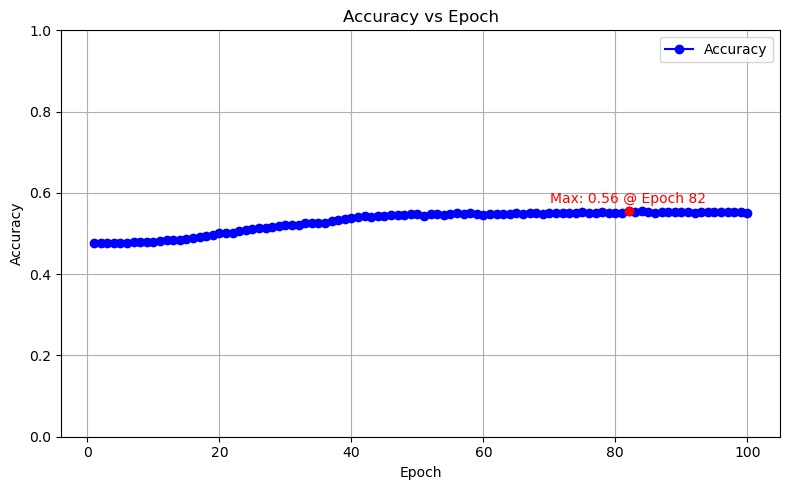

In [153]:
import matplotlib.pyplot as plt

# 生成横轴为 epoch
epochs = list(range(1, len(acc_list) + 1))

# 找到最高点位置和值
max_acc = max(acc_list)
max_epoch = acc_list.index(max_acc) + 1  # 注意加1，因为epoch从1开始

# 画图
plt.figure(figsize=(8, 5))
plt.plot(epochs, acc_list, marker='o', linestyle='-', color='b', label='Accuracy')

# 标记最高点
plt.scatter(max_epoch, max_acc, color='red', zorder=5)
plt.text(max_epoch, max_acc + 0.02, f'Max: {max_acc:.2f} @ Epoch {max_epoch}', color='red', ha='center')

# 图形美化
plt.title('Accuracy vs Epoch')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.ylim(0, 1)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


In [154]:
y_pred = model.predict(X_test)
acc = (y_pred == y_true_test).mean()
print(f"Accuracy: {acc:.4f}")


Accuracy: 0.5516
